In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

df = pd.read_csv("../data/processed/heart_clean.csv")

X = df.drop(columns=["target"])
y = df["target"]

numeric_features = ["age", "trestbps", "chol", "thalch", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope"]

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_pipeline = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("X:", X.shape, " y:", y.shape)

X: (918, 11)  y: (918,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

print("\nTrain class balance:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest class balance:")
print(y_test.value_counts(normalize=True).round(3))

Train: (734, 11) (734,)
Test:  (184, 11) (184,)

Train class balance:
target
1    0.553
0    0.447
Name: proportion, dtype: float64

Test class balance:
target
1    0.554
0    0.446
Name: proportion, dtype: float64


In [ ]:
print("Median cholesterol, ALL patients:  ", X["chol"].median())
print("Median cholesterol, TRAIN only:    ", X_train["chol"].median())
print("Median cholesterol, TEST only:     ", X_test["chol"].median())

Median cholesterol, ALL patients:   240.0
Median cholesterol, TRAIN only:     240.0
Median cholesterol, TEST only:      239.0


In [ ]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Train prepared:", X_train_prepared.shape)
print("Test prepared: ", X_test_prepared.shape)
print("Missing values left (train):", np.isnan(X_train_prepared).sum())
print("Missing values left (test): ", np.isnan(X_test_prepared).sum())

Train prepared: (734, 24)
Test prepared:  (184, 24)
Missing values left (train): 0
Missing values left (test):  0


In [ ]:
print("Train numeric means (should be ~0):")
print(X_train_prepared[:, :5].mean(axis=0).round(2))

print("\nTest numeric means (close to 0, but not exactly):")
print(X_test_prepared[:, :5].mean(axis=0).round(2))

Train numeric means (should be ~0):
[-0.  0.  0. -0. -0.]

Test numeric means (close to 0, but not exactly):
[-0.03 -0.   -0.05 -0.03 -0.01]


In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_prepared, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [ ]:
y_pred = log_reg.predict(X_test_prepared)

print("First 10 predictions:   ", y_pred[:10])
print("First 10 actual answers:", y_test.values[:10])

First 10 predictions:    [0 1 1 1 1 0 1 1 0 1]
First 10 actual answers: [1 1 1 1 0 0 0 1 0 1]


In [ ]:
proba = log_reg.predict_proba(X_test_prepared)

results = pd.DataFrame({
    "P(no disease)": proba[:, 0].round(3),
    "P(disease)": proba[:, 1].round(3),
    "Predicted": y_pred,
    "Actual": y_test.values
})

results.head(8)

,P(no disease),P(disease),Predicted,Actual
0,0.685,0.315,0,1
1,0.059,0.941,1,1
2,0.304,0.696,1,1
3,0.073,0.927,1,1
4,0.366,0.634,1,0
5,0.630,0.370,0,0
6,0.446,0.554,1,0
7,0.067,0.933,1,1


In [ ]:
train_acc = log_reg.score(X_train_prepared, y_train)
test_acc = log_reg.score(X_test_prepared, y_test)

print(f"Training accuracy: {train_acc:.3f}")
print(f"Test accuracy:     {test_acc:.3f}")

Training accuracy: 0.820
Test accuracy:     0.837


In [ ]:
feature_names = preprocessor.get_feature_names_out()

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": log_reg.coef_[0]
})

coef_table["abs_value"] = coef_table["coefficient"].abs()
coef_table.sort_values("abs_value", ascending=False).head(10).drop(columns="abs_value")

,feature,coefficient
7,cat__cp_asymptomatic,1.087725
13,cat__fbs_Unknown,0.964628
8,cat__cp_atypical angina,-0.875600
6,cat__sex_Male,0.749525
22,cat__slope_flat,0.734296
5,cat__sex_Female,-0.708963
11,cat__fbs_False,-0.662076
17,cat__exang_False,-0.609621
4,num__oldpeak,0.358202
3,num__thalch,-0.358025


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel()
print("\nTrue Negatives (TN): ", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP): ", tp)

[[64 18]
 [12 90]]

True Negatives (TN):  64
False Positives (FP): 18
False Negatives (FN): 12
True Positives (TP):  90


In [ ]:
print(y_test.shape, y_pred.shape)

(184,) (184,)


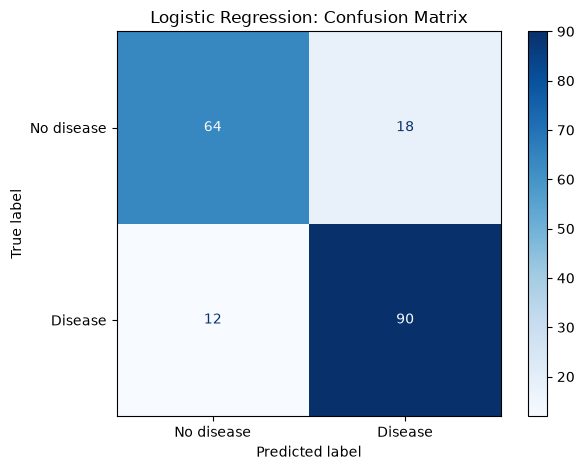

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No disease", "Disease"],
    cmap="Blues"
)
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrix_logreg.png", dpi=150)
plt.show()

In [ ]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 score:  {f1:.3f}")

Accuracy:  0.837
Precision: 0.833
Recall:    0.882
F1 score:  0.857


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred):.3f}")
print(f"F1 score:  {f1_score(y_test, y_pred):.3f}")

Accuracy:  0.837
Precision: 0.833
Recall:    0.882
F1 score:  0.857


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

              precision    recall  f1-score   support

  No disease       0.84      0.78      0.81        82
     Disease       0.83      0.88      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184



In [ ]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.3, 0.5, 0.7]:
    y_pred_t = (proba[:, 1] >= threshold).astype(int)
    p = precision_score(y_test, y_pred_t)
    r = recall_score(y_test, y_pred_t)
    missed = ((y_test.values == 1) & (y_pred_t == 0)).sum()
    print(f"Threshold {threshold}: precision={p:.3f}  recall={r:.3f}  missed cases={missed}")

Threshold 0.3: precision=0.773  recall=0.971  missed cases=3
Threshold 0.5: precision=0.833  recall=0.882  missed cases=12
Threshold 0.7: precision=0.882  recall=0.735  missed cases=27


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42
)
rf.fit(X_train_prepared, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [ ]:
rf_pred = rf.predict(X_test_prepared)
rf_proba = rf.predict_proba(X_test_prepared)

print(f"Training accuracy: {rf.score(X_train_prepared, y_train):.3f}")
print(f"Test accuracy:     {rf.score(X_test_prepared, y_test):.3f}")

Training accuracy: 0.871
Test accuracy:     0.832


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

print()
print(classification_report(y_test, rf_pred, target_names=["No disease", "Disease"]))

Confusion matrix:
[[63 19]
 [12 90]]

              precision    recall  f1-score   support

  No disease       0.84      0.77      0.80        82
     Disease       0.83      0.88      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184



In [ ]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

importance.head(10)

,feature,importance
7,cat__cp_asymptomatic,0.159980
18,cat__exang_True,0.101379
3,num__thalch,0.091088
17,cat__exang_False,0.087987
0,num__age,0.077815
8,cat__cp_atypical angina,0.074900
4,num__oldpeak,0.073463
22,cat__slope_flat,0.048448
5,cat__sex_Female,0.043424
2,num__chol,0.043111


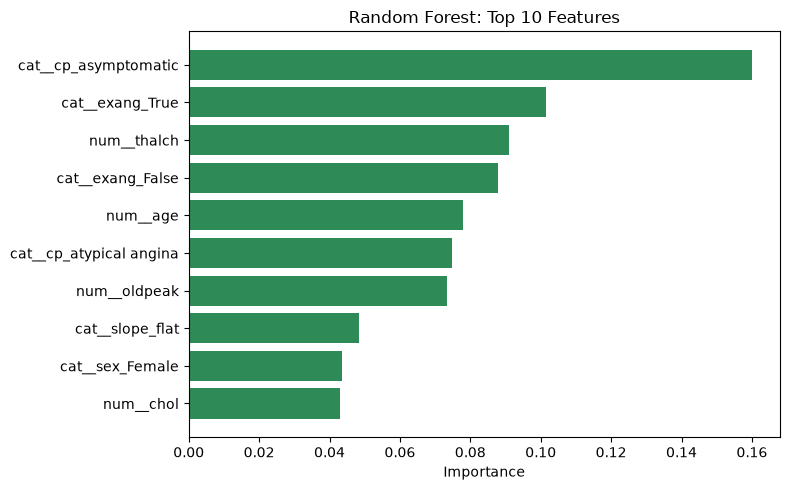

In [ ]:
import matplotlib.pyplot as plt

top = importance.head(10).iloc[::-1]

plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], color="seagreen")
plt.xlabel("Importance")
plt.title("Random Forest: Top 10 Features")
plt.tight_layout()
plt.savefig("../reports/figures/rf_feature_importance.png", dpi=150)
plt.show()

In [ ]:
rf_unlimited = RandomForestClassifier(n_estimators=300, random_state=42)
rf_unlimited.fit(X_train_prepared, y_train)

print(f"Unlimited trees, training accuracy: {rf_unlimited.score(X_train_prepared, y_train):.3f}")
print(f"Unlimited trees, test accuracy:     {rf_unlimited.score(X_test_prepared, y_test):.3f}")

Unlimited trees, training accuracy: 1.000
Unlimited trees, test accuracy:     0.821


In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)
xgb.fit(X_train_prepared, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
xgb_pred = xgb.predict(X_test_prepared)
xgb_proba = xgb.predict_proba(X_test_prepared)

print(f"Training accuracy: {xgb.score(X_train_prepared, y_train):.3f}")
print(f"Test accuracy:     {xgb.score(X_test_prepared, y_test):.3f}")

Training accuracy: 0.902
Test accuracy:     0.837


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion matrix:")
print(confusion_matrix(y_test, xgb_pred))

print()
print(classification_report(y_test, xgb_pred, target_names=["No disease", "Disease"]))

Confusion matrix:
[[63 19]
 [11 91]]

              precision    recall  f1-score   support

  No disease       0.85      0.77      0.81        82
     Disease       0.83      0.89      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184



In [ ]:
patient = X_train_prepared[:1]

for n_trees in [1, 5, 20, 50, 100, 200]:
    p = xgb.predict_proba(patient, iteration_range=(0, n_trees))[0, 1]
    print(f"Using first {n_trees:>3} trees -> P(disease) = {p:.3f}")

print("Actual answer for this patient:", y_train.iloc[0])

Using first   1 trees -> P(disease) = 0.559
Using first   5 trees -> P(disease) = 0.594
Using first  20 trees -> P(disease) = 0.684
Using first  50 trees -> P(disease) = 0.755
Using first 100 trees -> P(disease) = 0.809
Using first 200 trees -> P(disease) = 0.842
Actual answer for this patient: 1


In [ ]:
xgb_importance = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

xgb_importance.head(10)

,feature,importance
7,cat__cp_asymptomatic,0.232623
17,cat__exang_False,0.108375
18,cat__exang_True,0.098678
22,cat__slope_flat,0.049934
5,cat__sex_Female,0.046225
11,cat__fbs_False,0.039925
13,cat__fbs_Unknown,0.039888
8,cat__cp_atypical angina,0.036250
4,num__oldpeak,0.035533
6,cat__sex_Male,0.033559


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_predictions = {
    "Logistic Regression": y_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

rows = []
for name, preds in test_predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds)
    })

scoreboard = pd.DataFrame(rows).set_index("Model").round(3)
scoreboard

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.837,0.833,0.882,0.857
Random Forest,0.832,0.826,0.882,0.853
XGBoost,0.837,0.827,0.892,0.858


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "XGBoost": xgb
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "recall", "f1"]

cv_results = {}
for name, model in models.items():
    full_pipeline = Pipeline([
        ("prep", clone(preprocessor)),
        ("model", clone(model))
    ])
    scores = cross_validate(full_pipeline, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = scores
    print(f"Finished: {name}")

Finished: Logistic Regression
Finished: Random Forest
Finished: XGBoost


In [ ]:
summary_rows = []
for name, scores in cv_results.items():
    summary_rows.append({
        "Model": name,
        "Accuracy (mean)": scores["test_accuracy"].mean(),
        "Accuracy (std)": scores["test_accuracy"].std(),
        "Recall (mean)": scores["test_recall"].mean(),
        "F1 (mean)": scores["test_f1"].mean()
    })

cv_summary = pd.DataFrame(summary_rows).set_index("Model").round(3)
cv_summary

,Accuracy (mean),Accuracy (std),Recall (mean),F1 (mean)
Model,,,,
Logistic Regression,0.812,0.042,0.855,0.835
Random Forest,0.816,0.040,0.855,0.838
XGBoost,0.796,0.035,0.833,0.819


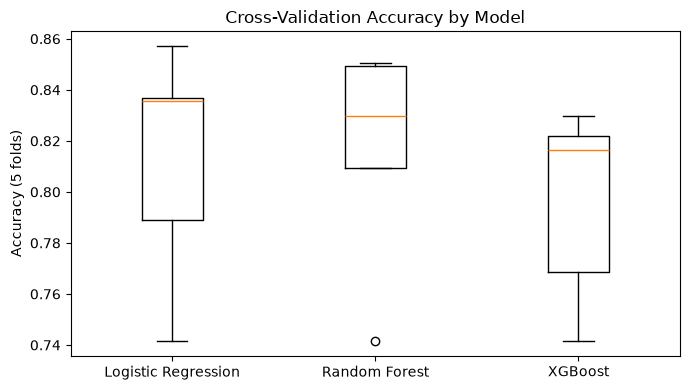

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.boxplot(
    [cv_results[name]["test_accuracy"] for name in models],
    tick_labels=list(models.keys())
)
plt.ylabel("Accuracy (5 folds)")
plt.title("Cross-Validation Accuracy by Model")
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison.png", dpi=150)
plt.show()

In [ ]:
best_name = cv_summary["F1 (mean)"].idxmax()
print("Highest mean CV F1:", best_name)

print("\nCV F1 means:")
print(cv_summary["F1 (mean)"])

Highest mean CV F1: Random Forest

CV F1 means:
Model
Logistic Regression    0.835
Random Forest          0.838
XGBoost                0.819
Name: F1 (mean), dtype: float64


In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

chosen_model = LogisticRegression(max_iter=1000, random_state=42)
# To switch models later, replace the line above, e.g.:
# chosen_model = clone(rf)    or    chosen_model = clone(xgb)

final_pipeline = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", chosen_model)
])

final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','sex','cp',...,'exang','oldpeak','slope']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not 

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

final_pred = final_pipeline.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, final_pred):.3f}")
print(f"Test recall:   {recall_score(y_test, final_pred):.3f}")
print(f"Test F1:       {f1_score(y_test, final_pred):.3f}")

Test accuracy: 0.837
Test recall:   0.882
Test F1:       0.857


In [ ]:
import joblib

joblib.dump(final_pipeline, "../models/heart_model.joblib")
print("Saved!")

Saved!


In [ ]:
import json
import sklearn

model_info = {
    "model_type": type(chosen_model).__name__,
    "sklearn_version": sklearn.__version__,
    "feature_columns": list(X_train.columns),
    "categories": {col: sorted(X_train[col].unique().tolist()) for col in categorical_features},
    "numeric_ranges": {
        col: [float(X_train[col].min()), float(X_train[col].max())]
        for col in numeric_features
    }
}

with open("../models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

print("scikit-learn version:", sklearn.__version__)
print(json.dumps(model_info["categories"], indent=2))

scikit-learn version: 1.9.1
{
  "sex": [
    "Female",
    "Male"
  ],
  "cp": [
    "asymptomatic",
    "atypical angina",
    "non-anginal",
    "typical angina"
  ],
  "fbs": [
    "False",
    "True",
    "Unknown"
  ],
  "restecg": [
    "lv hypertrophy",
    "normal",
    "st-t abnormality"
  ],
  "exang": [
    "False",
    "True",
    "Unknown"
  ],
  "slope": [
    "Unknown",
    "downsloping",
    "flat",
    "upsloping"
  ]
}


In [ ]:
loaded_model = joblib.load("../models/heart_model.joblib")

new_patient = pd.DataFrame([{
    "age": 55,
    "sex": "Male",
    "cp": "asymptomatic",
    "trestbps": 140,
    "chol": 230,
    "fbs": "False",
    "restecg": "normal",
    "thalch": 120,
    "exang": "True",
    "oldpeak": 1.5,
    "slope": "flat"
}])

prob = loaded_model.predict_proba(new_patient)[0, 1]
label = loaded_model.predict(new_patient)[0]

print(f"P(disease) = {prob:.3f}")
print("Prediction:", "Disease likely" if label == 1 else "Disease unlikely")

P(disease) = 0.934
Prediction: Disease likely


In [ ]:
same = (loaded_model.predict(X_test) == final_pred).all()
print("Loaded model gives identical predictions:", same)

Loaded model gives identical predictions: True
